# EDA: Pakistan Weather and Air Quality
Data comes from weather.db (created by etl.py).

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_sql("SELECT * FROM readings", sqlite3.connect("weather.db"), parse_dates=["time"])
df["month"] = df["time"].dt.to_period("M").astype(str)
df.head()

,city,time,temperature,humidity,rain,wind,pm25,pm10,aqi,date,month
0,Lahore,2024-01-01 00:00:00,6.2,99.0,0.0,3.4,260.8,375.3,272.0,2024-01-01,2024-01
1,Lahore,2024-01-01 01:00:00,6.1,98.0,0.0,2.3,260.8,375.3,273.0,2024-01-01,2024-01
2,Lahore,2024-01-01 02:00:00,6.4,99.0,0.0,2.2,239.3,344.6,273.0,2024-01-01,2024-01
3,Lahore,2024-01-01 03:00:00,6.2,100.0,0.0,3.1,208.6,299.0,273.0,2024-01-01,2024-01
4,Lahore,2024-01-01 04:00:00,6.6,97.0,0.0,3.1,196.0,281.3,273.0,2024-01-01,2024-01


## 1. Data overview and missing values

In [2]:
print(df.shape)
print(df.isna().sum())
df.describe()

(87720, 11)
city           0
time           0
temperature    0
humidity       0
rain           0
wind           0
pm25           0
pm10           0
aqi            0
date           0
month          0
dtype: int64


,time,temperature,humidity,rain,wind,pm25,pm10,aqi
count,87720,87720.000000,87720.000000,87720.000000,87720.000000,87720.000000,87720.000000,87720.000000
mean,2024-12-31 11:29:59.999999,22.543189,56.807866,0.072967,7.659640,38.089991,68.272882,107.172093
min,2024-01-01 00:00:00,-4.900000,2.000000,0.000000,0.000000,0.300000,0.400000,22.000000
25%,2024-07-01 17:45:00,16.000000,37.000000,0.000000,3.700000,19.000000,33.800000,76.000000
50%,2024-12-31 11:30:00,24.100000,60.000000,0.000000,6.500000,29.000000,52.300000,96.000000
75%,2025-07-02 05:15:00,29.200000,78.000000,0.000000,10.200000,46.000000,82.400000,133.000000
max,2025-12-31 23:00:00,46.500000,100.000000,19.900000,46.600000,365.100000,890.300000,538.000000
std,NaN,8.893290,24.756897,0.570303,5.529768,31.971663,57.720090,42.549380


## 2. Outliers
Boxplot of PM2.5 for each city. Dots outside the box are outliers.

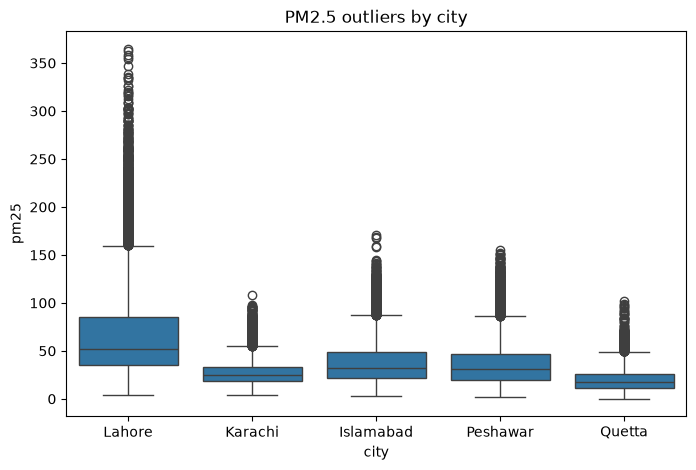

In [3]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="city", y="pm25")
plt.title("PM2.5 outliers by city")
plt.show()

## 3. Temperature over time

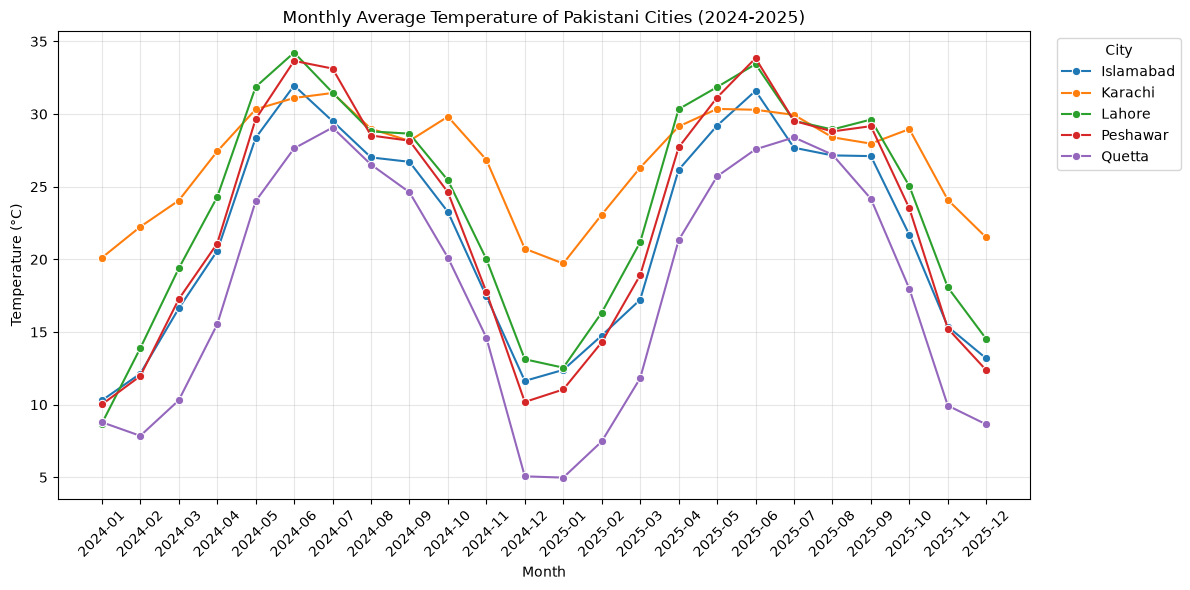

In [4]:
monthly = df.groupby(["month", "city"])["temperature"].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly, x="month", y="temperature", hue="city", marker="o")
plt.title("Monthly Average Temperature of Pakistani Cities (2024-2025)")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 4. Rain over time

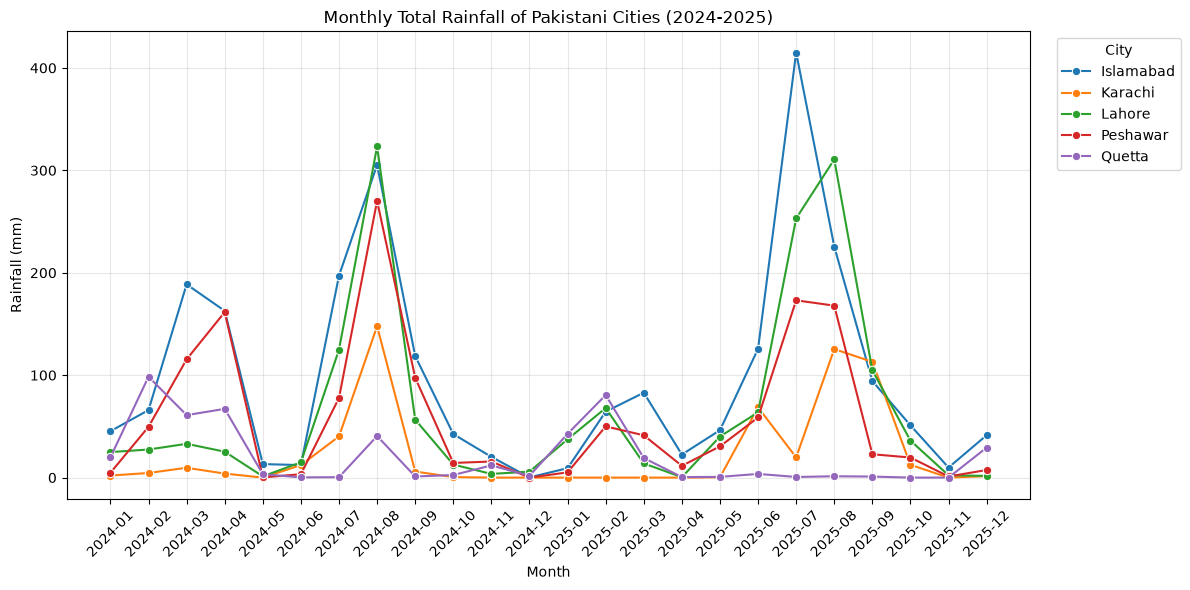

In [5]:
rain = df.groupby(["month", "city"])["rain"].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=rain, x="month", y="rain", hue="city", marker="o")
plt.title("Monthly Total Rainfall of Pakistani Cities (2024-2025)")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 5. Compare the cities

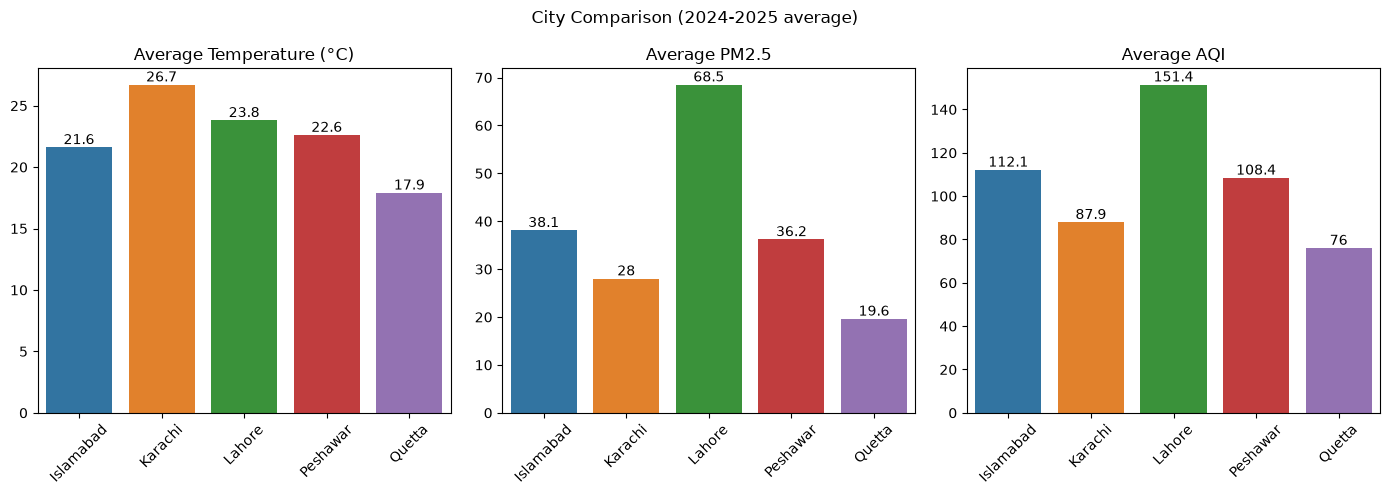

In [6]:
avg = df.groupby("city")[["temperature", "pm25", "aqi"]].mean().round(1)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
titles = ["Average Temperature (°C)", "Average PM2.5", "Average AQI"]

for ax, col, title in zip(axes, avg.columns, titles):
    sns.barplot(x=avg.index, y=avg[col], hue=avg.index, legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)
    for bar in ax.containers:
        ax.bar_label(bar)

plt.suptitle("City Comparison (2024-2025 average)")
plt.tight_layout()
plt.show()

## 6. Weather vs air quality

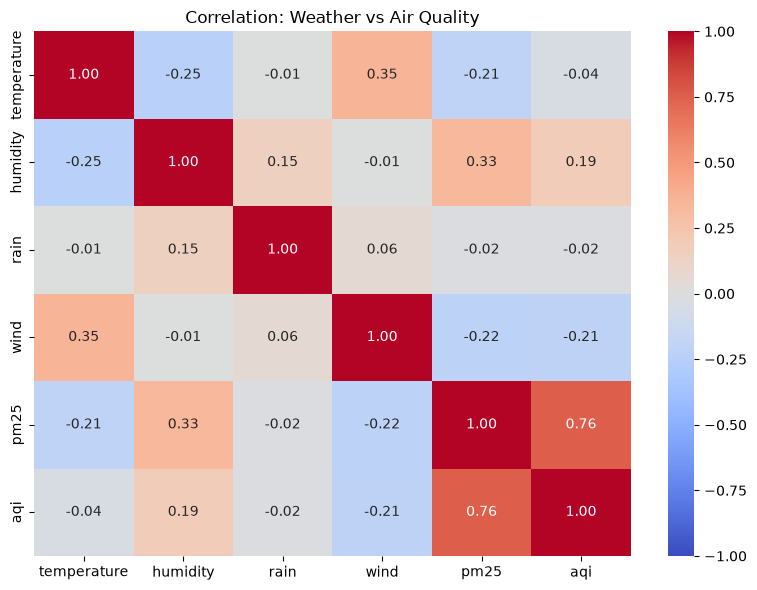

In [7]:
cols = ["temperature", "humidity", "rain", "wind", "pm25", "aqi"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation: Weather vs Air Quality")
plt.tight_layout()
plt.show()

## Conclusion
- Data was clean after the ETL step: no missing values and no impossible values.
- Temperature follows a clear seasonal pattern in all cities. Quetta is the coolest and Karachi is the warmest.
- Rain peaks in the monsoon months (July-August). Islamabad and Lahore get the most rain, and Karachi and Quetta are mostly dry.
- Lahore has the worst air quality (average AQI about 151) and the most extreme pollution spikes. Quetta has the cleanest air.
- Weather and air quality are only weakly related. Humidity has the strongest link with PM2.5 (+0.33), while wind and temperature have small negative links. This shows a relation, not a cause.